# Online Payment Fraud — Transactional Features

Different framing from the credit-card PCA-features project. Here the features are the kind of thing a payments processor actually sees: transaction amount, hour of day, merchant category, billing/IP country mismatch, account age, etc. No anonymized V-columns.

I'm synthesizing the dataset because I don't have a real one. The injection rules are deliberately not too obvious — fraud probability rises with country mismatch and unusual hour, but not deterministically — so the classifier has to actually do work.

In [1]:
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             confusion_matrix, classification_report)

rng = np.random.default_rng(11)
OUT = Path('../../data/payment_fraud')
OUT.mkdir(parents=True, exist_ok=True)

In [2]:
N = 20000
MERCH = ['groceries','electronics','gaming','travel','utilities','crypto','restaurants','jewelry']
df = pd.DataFrame({
    'amount':           rng.gamma(2.0, 80, N).round(2),
    'hour':             rng.integers(0, 24, N),
    'merchant_cat':     rng.choice(MERCH, N),
    'country_mismatch': rng.choice([0, 1], N, p=[0.95, 0.05]),
    'account_age_days': rng.integers(1, 2000, N),
    'n_tx_24h':         rng.poisson(3, N),
    'is_card_present':  rng.choice([0, 1], N, p=[0.4, 0.6]),
})

# fraud probability is a soft function of risk signals -- not a hard rule
risk = (
    0.02
    + 0.25 * df['country_mismatch']
    + 0.04 * ((df['hour'] < 5) | (df['hour'] > 22)).astype(int)
    + 0.06 * (df['merchant_cat'].isin(['crypto','jewelry','gaming']).astype(int))
    + 0.0002 * df['amount']
    - 0.04 * df['is_card_present']
    - 0.00005 * df['account_age_days']
).clip(0.001, 0.9)
df['is_fraud'] = (rng.random(N) < risk).astype(int)
df.to_csv(OUT / 'payments.csv', index=False)
print('rows', len(df), '| fraud rate', df['is_fraud'].mean().round(4))
df.head(4)

rows 20000 | fraud rate 0.0391


,amount,hour,merchant_cat,country_mismatch,account_age_days,n_tx_24h,is_card_present,is_fraud
0,136.90,5,electronics,0,245,1,0,0
1,304.04,4,crypto,0,1540,2,0,0
2,104.87,19,jewelry,0,432,4,0,0
3,201.25,12,gaming,0,941,1,1,0


## Quick EDA

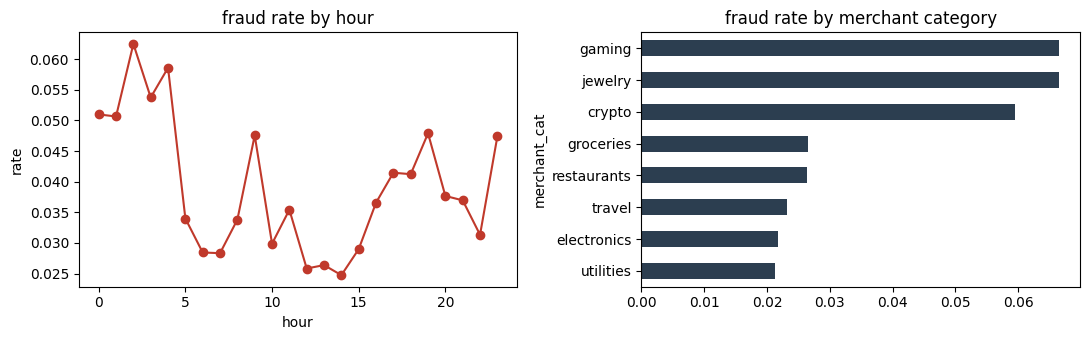

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df.groupby('hour')['is_fraud'].mean().plot(ax=ax[0], color='#c0392b', marker='o')
ax[0].set_title('fraud rate by hour'); ax[0].set_ylabel('rate')
df.groupby('merchant_cat')['is_fraud'].mean().sort_values().plot.barh(ax=ax[1], color='#2c3e50')
ax[1].set_title('fraud rate by merchant category')
plt.tight_layout(); plt.show()

In [4]:
# One-hot the merchant category. Tree models can use raw ordinals but keeping this simple.
feat = pd.get_dummies(df.drop(columns=['is_fraud']), columns=['merchant_cat'], drop_first=True)
X = feat.values
y = df['is_fraud'].values

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print('train', X_tr.shape, 'pos', y_tr.sum(), '| test', X_te.shape, 'pos', y_te.sum())

train (15000, 13) pos 587 | test (5000, 13) pos 195


In [5]:
rf = RandomForestClassifier(n_estimators=300, max_depth=None,
                            class_weight='balanced', n_jobs=-1, random_state=42)
rf.fit(X_tr, y_tr)
proba = rf.predict_proba(X_te)[:, 1]
print(f'ROC-AUC  {roc_auc_score(y_te, proba):.4f}')
print(f'PR-AUC   {average_precision_score(y_te, proba):.4f}')

ROC-AUC  0.8304
PR-AUC   0.1607


In [6]:
# threshold sweep -- the operating point matters more than a single F1 number
rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    rows.append({'thresh': t, 'tp': tp, 'fp': fp, 'fn': fn,
                 'precision': tp / max(tp + fp, 1),
                 'recall':    tp / max(tp + fn, 1)})
pd.DataFrame(rows)

,thresh,tp,fp,fn,precision,recall
0,0.2,39,148,156,0.208556,0.200000
1,0.3,18,44,177,0.290323,0.092308
2,0.4,8,17,187,0.320000,0.041026
3,0.5,3,5,192,0.375000,0.015385
4,0.6,0,2,195,0.000000,0.000000
5,0.7,0,0,195,0.000000,0.000000


In [7]:
# Top-k feature importance. Country mismatch and amount usually dominate.
imp = pd.Series(rf.feature_importances_, index=feat.columns).sort_values(ascending=False).head(10)
imp

account_age_days            0.247850
amount                      0.228707
hour                        0.147013
country_mismatch            0.131687
n_tx_24h                    0.090446
is_card_present             0.033612
merchant_cat_gaming         0.021958
merchant_cat_jewelry        0.019075
merchant_cat_electronics    0.017911
merchant_cat_restaurants    0.016445
dtype: float64

## Takeaways

- Because I wrote the data-generating process, the model is going to recover whatever I put in. Country mismatch and amount are usually the top two importances and that's by construction. On real data nothing is this neat.
- The threshold sweep is the only table here that matters operationally. At t=0.5 the model is too conservative — most fraud is missed. Lowering the threshold trades precision for recall; the right value depends on the alert-team capacity.
- Next pass: add velocity features (count of transactions in last 1h, last 24h per user) and a synthetic adversary that adapts to the model.